# Interpolation, exact risk and optimization bias
Separate training fit from population prediction and parameter norm from
parameter direction. [Chapter](../docs/04_generalization.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Verify the exact population-risk identity
For an independent isotropic Gaussian $x$, expected squared coefficient error
is $\|\hat w-\beta\|^2$. Add observation noise variance for prediction of $y$.

In [2]:
rng = np.random.default_rng(9)
beta = np.array([1., .5, 0., 0.])
w = np.array([.8, .7, -.2, .1])
x = rng.normal(size=(100000,4))
noise = rng.normal(scale=.5,size=len(x))
empirical = np.mean((x@beta + noise - x@w)**2)
exact = np.sum((beta-w)**2) + .25
print({'empirical_mse': empirical, 'exact_mse': exact})
assert abs(empirical-exact) < .01

{'empirical_mse': 0.3820090360194478, 'exact_mse': 0.38}


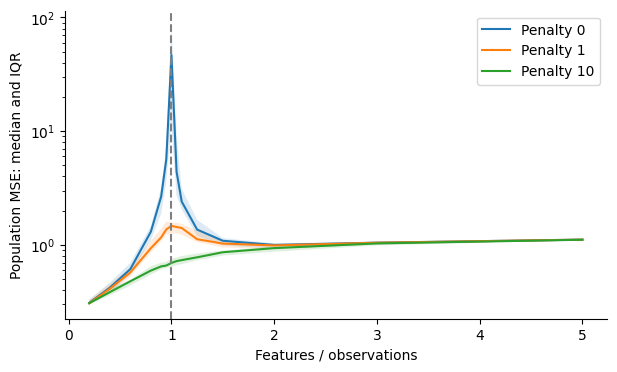

In [3]:
metrics = evidence('generalization')
rows = pd.DataFrame(metrics['double_descent'])
for penalty, frame in rows.groupby('penalty'):
    stats = frame.groupby('ratio').population_mse.quantile([.25,.5,.75]).unstack()
    plt.semilogy(stats.index, stats[.5], label=f'Penalty {penalty}')
    plt.fill_between(stats.index, stats[.25], stats[.75], alpha=.15)
plt.axvline(1,color='gray',linestyle='--')
plt.xlabel('Features / observations'); plt.ylabel('Population MSE: median and IQR'); plt.legend(); plt.show()

## Optimization can select a direction while norm diverges
Logistic loss on separable data has no finite minimizer. Inspect both quantities
alongside the hard-margin direction, rather than claiming parameter convergence.

,step,loss,norm,direction_cosine,normalized_margin
0,1,0.642702,0.072650,0.843025,-1.496320
85,30000,0.001461,10.757591,0.999999,0.384546


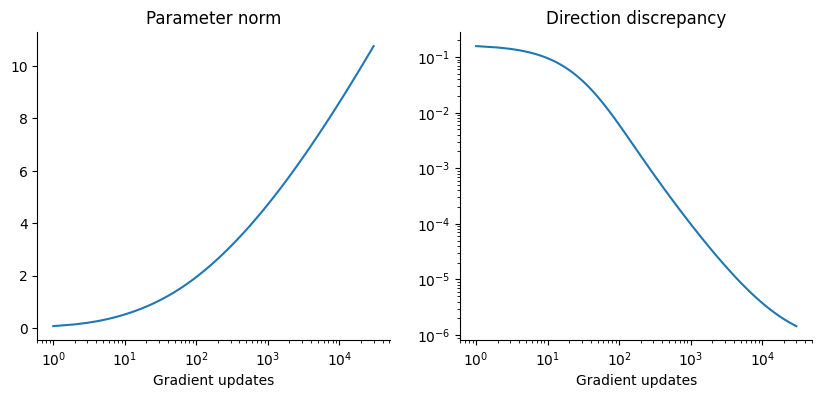

In [4]:
implicit = pd.DataFrame(metrics['implicit_bias'])
display(implicit.iloc[[0,-1]])
fig,axes = plt.subplots(1,2,figsize=(10,4))
axes[0].semilogx(implicit.step,implicit.norm); axes[0].set_title('Parameter norm')
axes[1].loglog(implicit.step,1-implicit.direction_cosine); axes[1].set_title('Direction discrepancy')
for ax in axes: ax.set_xlabel('Gradient updates')
plt.show()

## Nonlinear features at limited label budgets
The offline digit study uses the same test set across all budgets. Validation
selects regularization; test labels do not determine settings.

In [5]:
pd.DataFrame(evidence('kernels')['rows']).groupby(['model','train_size']).accuracy.agg(['mean','std'])

mean       std
model    train_size                    
logistic 100         0.895556  0.027035
         300         0.931852  0.006789
         1000        0.967407  0.004626
nystroem 100         0.888148  0.028138
         300         0.937778  0.013878
         1000        0.968148  0.001283
rbf_svm  100         0.893333  0.034211
         300         0.945185  0.024977
         1000        0.975556  0.004444

## Exercise and worked answer
Would the interpolation curve have the same interpretation if widths below ten
omitted true signal coordinates? No. Approximation error would then change with
width. The reference experiment includes all ten signal features at every width,
isolating noise amplification and regularization more directly. Its conclusions
concern the declared Gaussian model, not every deep learning architecture.